# Check simpsons predictions

In [1]:
import torch
import torchvision
import simpsons
import json
from simpsons.dataset import SimpsonsDataset, preload_dataset, SimpsonsDatasetInMemory
from simpsons.models.simpsons_net_conv import SimpsonsNetConv

/beegfs/.global0/ws/clehm-inferential_statistics_ml/.dev/.venvs/venv_simpsons-4e469e42-jupyter/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [39]:
with open(
        "/beegfs/ws/0/clehm-inferential_statistics_ml/.dev/.yahor/tmp/results/result-simpsons-pred-research-925b3ca0-29c0-40b2-ab7f-3762ea2c3625.json") as file:
    results = json.load(file)

train_idx = test_idx = results["result_data"]["train_metrics"][0]["train_indices"]
test_idx = results["result_data"]["train_metrics"][0]["test_indices"]
test_error_rate = results["result_data"]["target_metric_value"]

print(f"Train size: {len(train_idx)}")
print(f"Test size: {len(test_idx)}")
print(f"Accuracy on test: {1 - test_error_rate}")

Train size: 16746
Test size: 4187
Accuracy on test: 0.8538332935275854


In [34]:
dataset_full: SimpsonsDataset = SimpsonsDataset(
    "/beegfs/ws/0/clehm-inferential_statistics_ml/simpsons/data/raw/dataset"
)

dataset_64x64: SimpsonsDatasetInMemory = preload_dataset(SimpsonsDataset(
    "/beegfs/ws/0/clehm-inferential_statistics_ml/simpsons/data/processed/dataset_64x64",
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor()])
))

dataset_64x64

Dataset SimpsonsDatasetInMemory
    Number of datapoints: 20933
    Root location: /beegfs/ws/0/clehm-inferential_statistics_ml/simpsons/data/processed/dataset_64x64
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [40]:
model = SimpsonsNetConv(input_shape=(64, 64, 3), num_classes=len(dataset_64x64.classes))

model.load_state_dict(torch.load(results["experiment_setup"]["path_to_trained_model"]))
model.eval()

model

SimpsonsNetConv(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (5): Dropout(p=0.2, inplace=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (9): ReLU()
  (10): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (11): Dropout(p=0.2, inplace=False)
  (12): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (13): ReLU()
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
  (15): ReLU()
  (16): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (17): Dropout(p=0.2, inplace=False)
  (18): Flatten(start_dim=1, end_dim=-1)
  (19): Linear(in_features=9216, out_features=1024, bias=True)
  (20): ReLU()

In [41]:
def predict(
        data_loader: torch.utils.data.DataLoader,
        device,
        model,
) -> tuple[torch.Tensor, torch.Tensor, float, float]:
    with torch.no_grad():
        outputs_batched: list[torch.Tensor] = []
        preds_batched: list[torch.Tensor] = []
        labels_batched: list[torch.Tensor] = []

        for features_batch, labels_batch in data_loader:
            # Move to gpu
            features_batch: torch.Tensor = features_batch.to(device)  # (B, C, H, W)
            labels_batch: torch.Tensor = labels_batch.to(device)  # (B,)

            # Forward pass
            outputs_batch = model.forward(features_batch)  # (B, N_c)
            outputs_batched.append(outputs_batch)  # Outputs are on {device}!

            # Get predictions
            _, class_idx_batch = torch.max(input=outputs_batch, dim=1)
            preds_batched.append(class_idx_batch.detach().cpu())
            labels_batched.append(labels_batch.detach().cpu())

        # Predictions, labels, outputs for all data from data_loader
        preds_dataset = torch.hstack(preds_batched)
        labels_dataset = torch.hstack(labels_batched)
        outputs_dataset = torch.vstack(outputs_batched)

        print(int((preds_dataset == labels_dataset).sum()) / len(labels_dataset))

        return preds_dataset, labels_dataset


device = torch.device('cuda')

model.to(device)

test_dataset = torch.utils.data.Subset(dataset_64x64, test_idx)

test_data_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=len(test_dataset),
    shuffle=False
)
preds_test_dataset, labels_test_dataset = predict(test_data_loader, device, model)

0.8538332935275854


In [32]:
import sklearn.metrics

sklearn.metrics.accuracy_score(labels_test_dataset, preds_test_dataset)

0.8340100310484834

In [23]:
import numpy as np


def cls_index_to_cls_name(index: int) -> str:
    for class_name, class_index in dataset_64x64.class_to_idx.items():
        if index == class_index:
            return class_name


pred_diff = np.equal(preds_test_dataset.numpy(), labels_test_dataset.numpy())
index = test_dataset.indices
incorrect = []
correct = []
for i, is_correct, y_hat, y in zip(index, pred_diff, preds_test_dataset.numpy(), labels_test_dataset.numpy()):
    img_tensor, img_cls = dataset_64x64[i]
    if not is_correct:
        incorrect.append((i, img_tensor, cls_index_to_cls_name(y_hat), cls_index_to_cls_name(y)))
    else:
        correct.append((i, img_tensor, cls_index_to_cls_name(y_hat), cls_index_to_cls_name(y)))
print("Incorrect predicted:", len(incorrect))

Incorrect predicted: 139


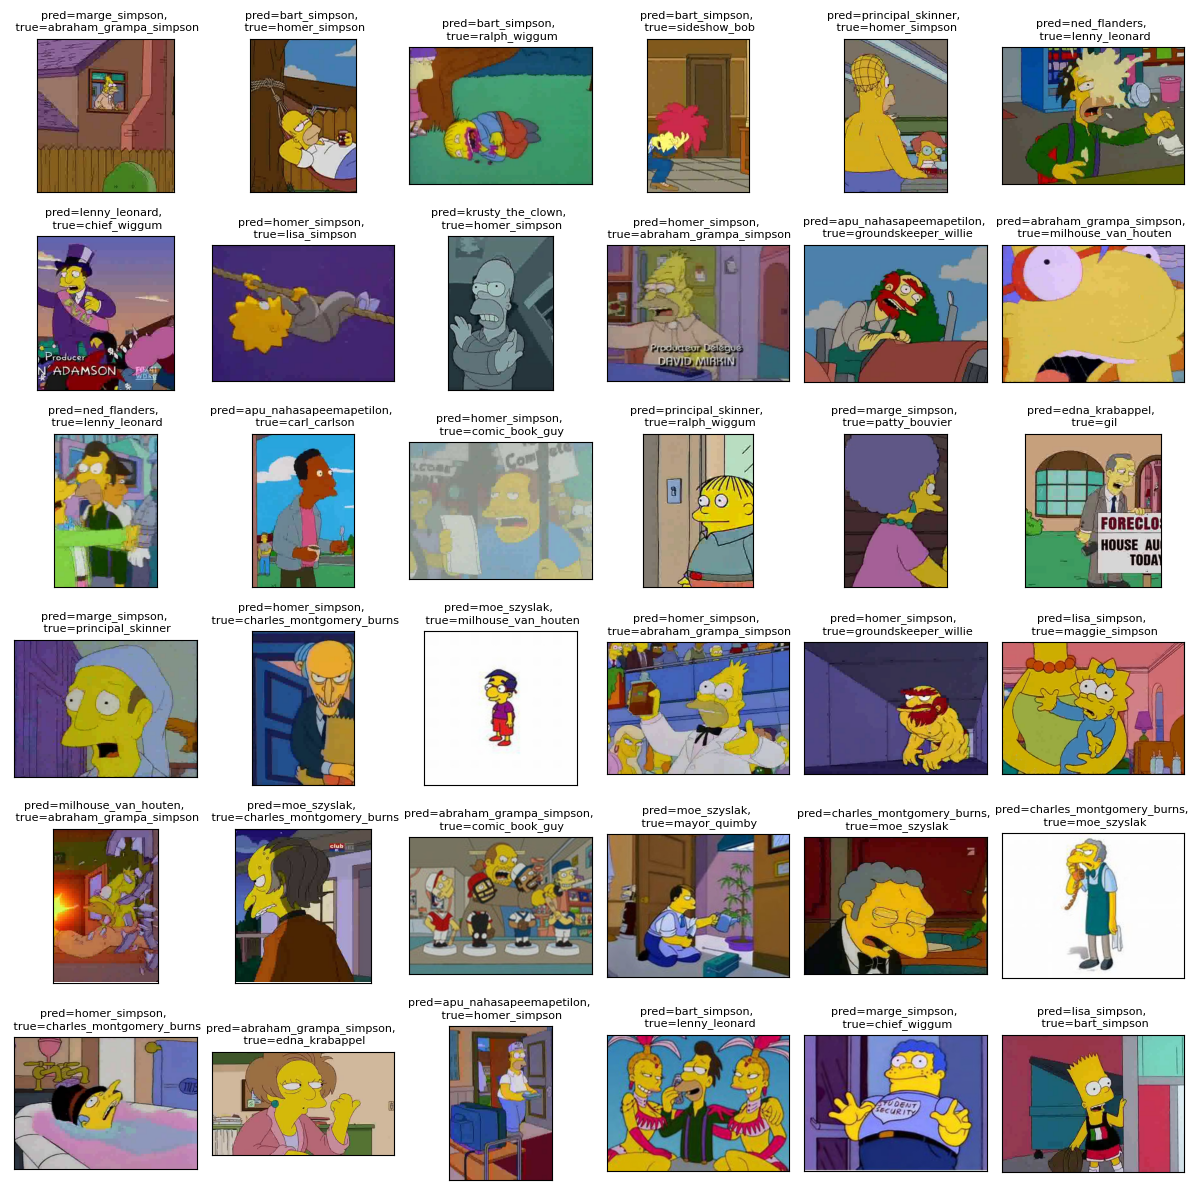

In [20]:
import matplotlib.pyplot as plt

fig, ax_arr = plt.subplots(6, 6, figsize=(12, 12))

sample_idx = np.random.choice(len(incorrect), 36, replace=False)
sample = [incorrect[i] for i in sample_idx]

for i, ax in enumerate(ax_arr.flatten()):
    i, _, cls_pred, cls_true = sample[i]
    img_pil, cls_index_true = dataset_full[i]

    assert cls_index_to_cls_name(cls_index_true) == cls_true

    ax.tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)

    ax.imshow(np.array(img_pil))
    ax.set_title(f"pred={cls_pred}, \n true={cls_true}", fontsize=8)

fig.tight_layout()

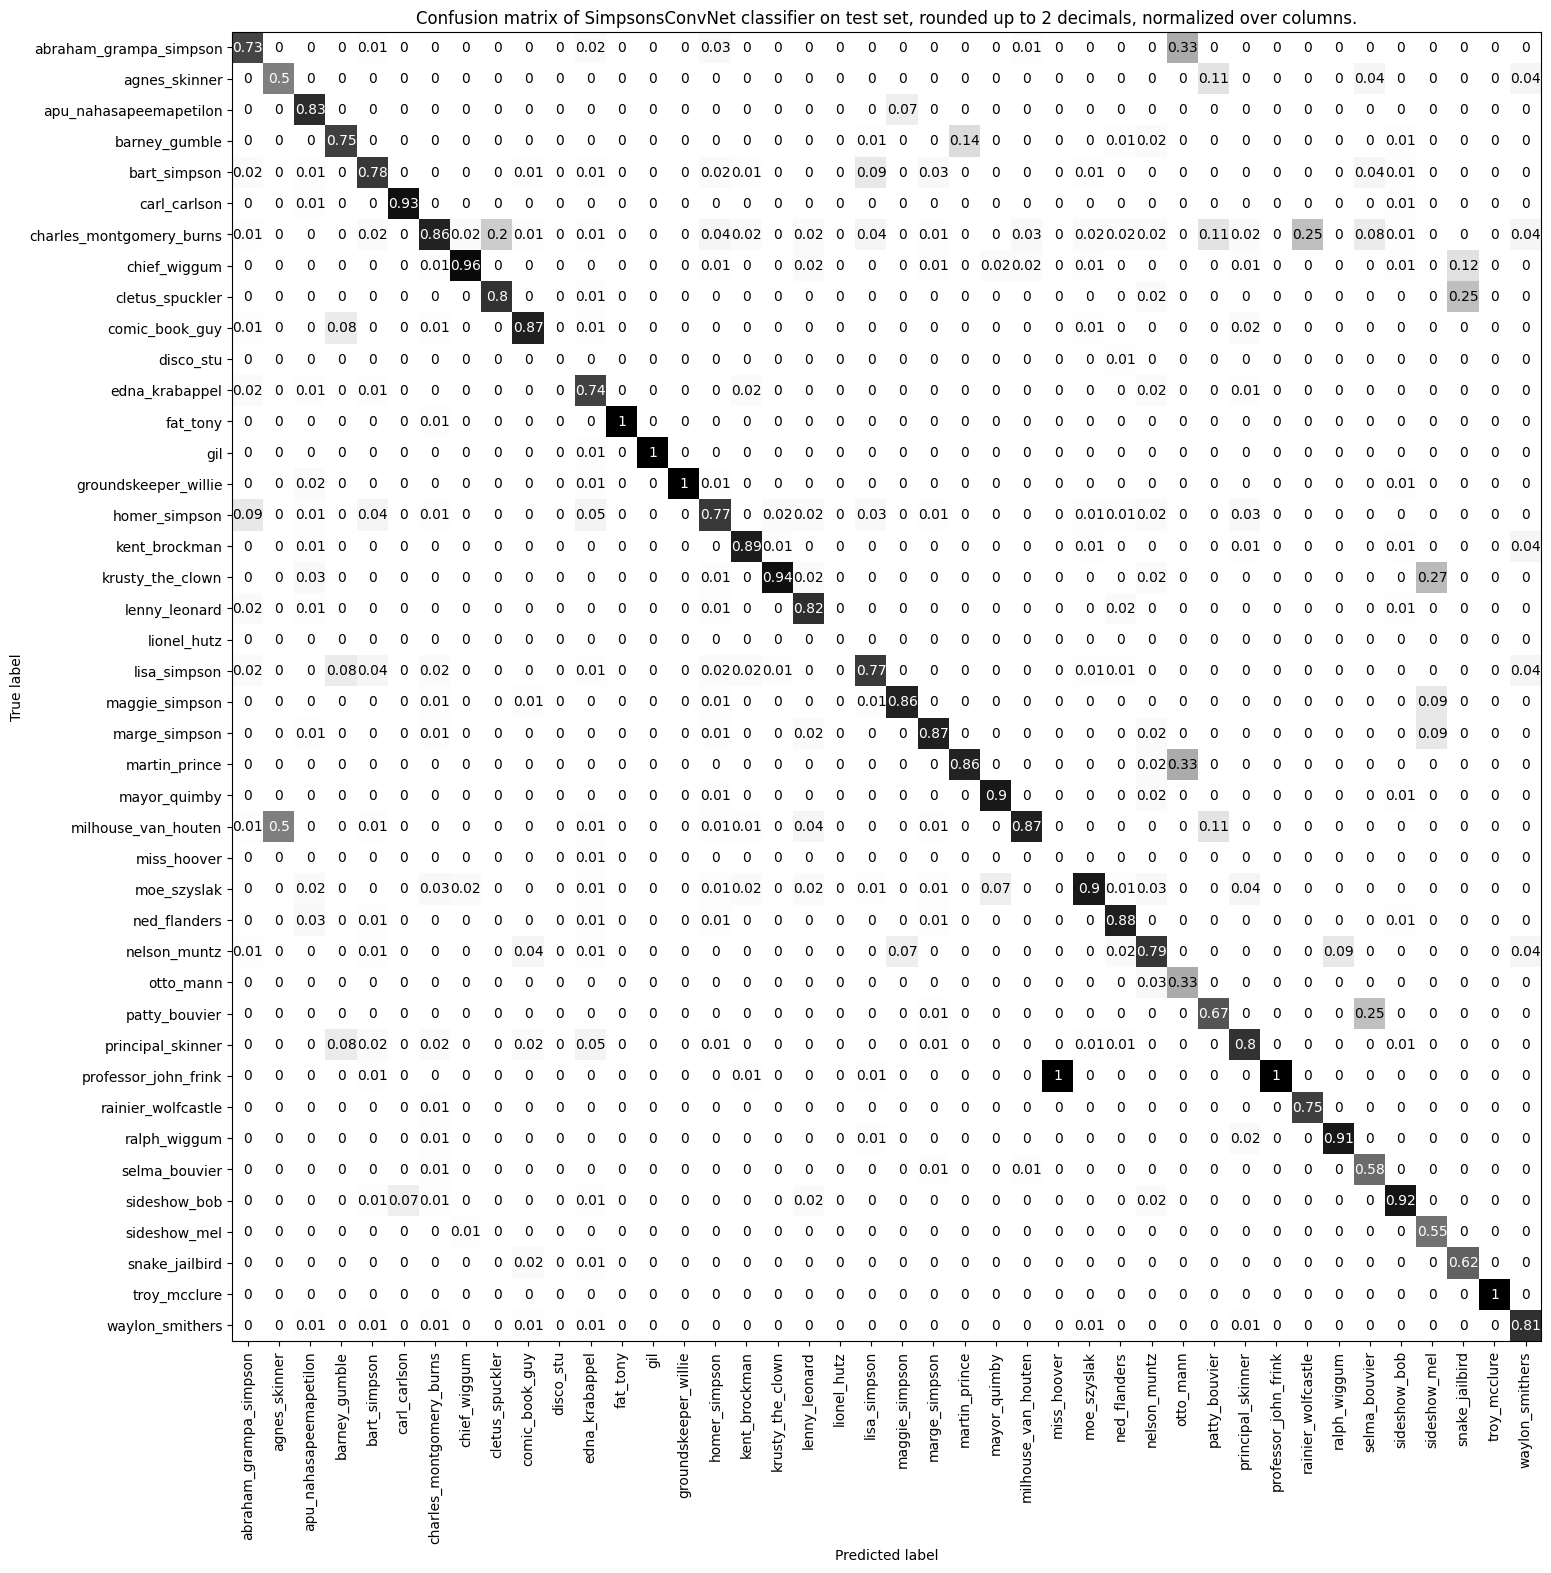

In [21]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import pandas as pd

cls_true = [cls_index_to_cls_name(i) for i in labels_test_dataset]
cls_pred = [cls_index_to_cls_name(i) for i in preds_test_dataset]
cls_labels = list(dataset_64x64.class_to_idx.keys())

#conf_mat = np.array2string(confusion_matrix(cls_true, cls_pred, labels=cls_labels))
#class_rep_conf_mat = classification_report(cls_true, cls_pred, labels=cls_labels, digits=5)
#class_rep_dict = classification_report(cls_true, cls_pred, labels=cls_labels, output_dict=True)
# creating confusion matrix with pandas for getting labels displayed
#conf_mat_pd = pd.crosstab(cls_true, cls_pred, rownames=['True'], colnames=['Predicted'], margins=True)

conf_matrix = np.round(confusion_matrix(cls_true, cls_pred, labels=cls_labels, normalize="pred"), decimals=2)
d = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=cls_labels)

fig, ax = plt.subplots(figsize=(17, 17))
ax.set_title(
    "Confusion matrix of SimpsonsConvNet classifier on test set, rounded up to 2 decimals, normalized over columns.")
d.plot(ax=ax, xticks_rotation='vertical', cmap="binary", colorbar=False)

In [22]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import numpy as np
import PIL
from PIL.Image import Image
import cv2

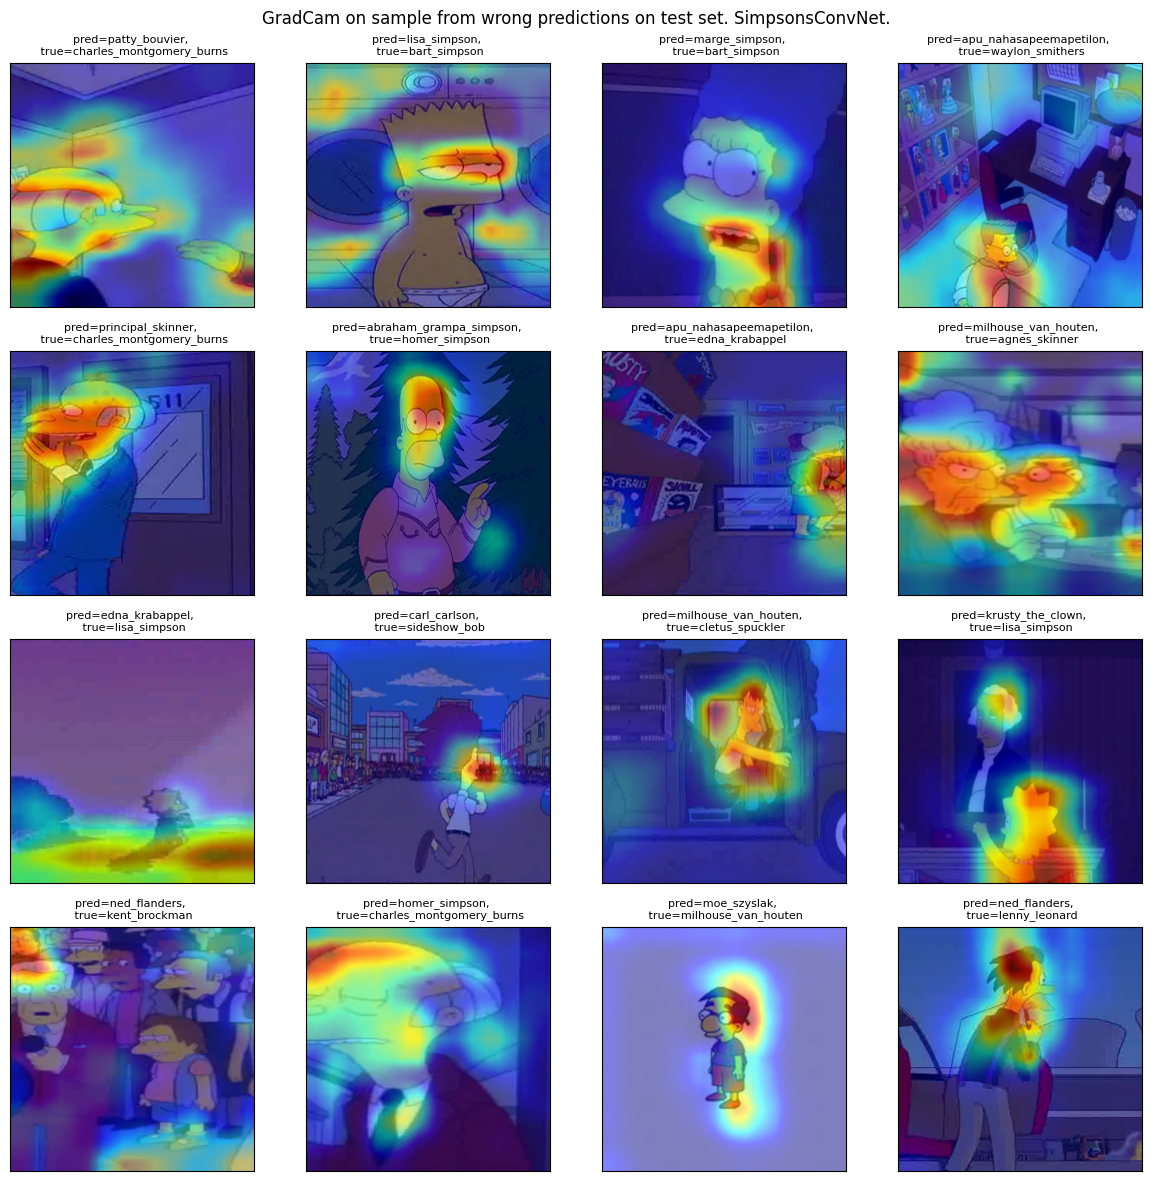

In [23]:
def show_cam_on_scaled_image(
        img: np.ndarray,
        mask: np.ndarray,
        use_rgb: bool = False,
        colormap: int = cv2.COLORMAP_JET,
        image_weight: float = 0.5
) -> np.ndarray:
    heatmap = cv2.applyColorMap(np.uint8(255 * mask), colormap)
    if use_rgb:
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    heatmap = np.float32(heatmap) / 255

    hatmap_pil = PIL.Image.fromarray((heatmap * 255).astype(np.uint8))
    heatmap_pil_resized = hatmap_pil.resize(img.shape[:2])

    heatmap_resized = np.float32(np.array(heatmap_pil_resized)) / 255

    if np.max(img) > 1:
        raise Exception(
            "The input image should np.float32 in the range [0, 1]")

    if image_weight < 0 or image_weight > 1:
        raise Exception(
            f"image_weight should be in the range [0, 1].\
                Got: {image_weight}")

    cam = (1 - image_weight) * heatmap_resized + image_weight * img
    cam = cam / np.max(cam)
    return np.uint8(255 * cam)


def apply_gradcam(
        input_idx: int,
        dataset_processed: SimpsonsDatasetInMemory,
        dataset_raw: SimpsonsDataset,
        model: SimpsonsNetConv,
        target_layers: list[torch.nn.Module]
) -> Image:
    input_tensor_processed, input_cls_idx = dataset_processed[input_idx]
    input_pil_processed: Image = torchvision.transforms.ToPILImage()(input_tensor_processed)
    input_rgb_processed: np.ndarray = np.float32(np.array(input_pil_processed)) / 255

    input_batch_processed: torch.Tensor = torch.unsqueeze(input_tensor_processed, 0)

    input_pil_raw, _ = dataset_raw[input_idx]

    input_pil_raw_rect = input_pil_raw.resize((512, 512))
    input_rgb_raw_rect: np.ndarray = np.float32(np.array(input_pil_raw_rect)) / 255

    cam = GradCAM(model=model, target_layers=target_layers, use_cuda=True)
    targets = [ClassifierOutputTarget(input_cls_idx)]
    grayscale_cam = cam(input_tensor=input_batch_processed, targets=targets)
    grayscale_cam = grayscale_cam[0, :]
    visualization = show_cam_on_scaled_image(input_rgb_raw_rect, grayscale_cam, use_rgb=True)

    return PIL.Image.fromarray(visualization)


fig, ax_arr = plt.subplots(4, 4, figsize=(12, 12))

fig.suptitle("GradCam on sample from wrong predictions on test set. SimpsonsConvNet.")

sample_idx = np.random.choice(len(incorrect), 16, replace=False)
sample = [incorrect[i] for i in sample_idx]

for i, ax in enumerate(ax_arr.flatten()):
    i, _, cls_pred, cls_true = sample[i]
    img_pil, cls_index_true = dataset_full[i]

    assert cls_index_to_cls_name(cls_index_true) == cls_true

    ax.tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)

    ax.imshow(np.array(
        apply_gradcam(
            input_idx=i,
            dataset_raw=dataset_full,
            dataset_processed=dataset_64x64,
            model=model,
            target_layers=list(model.children())[-11:-6]
        )
    ))
    ax.set_title(f"pred={cls_pred}, \n true={cls_true}", fontsize=8)

fig.tight_layout()

/tmp/ipykernel_165708/4074482911.py:5: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  sample = np.array(correct)[np.random.choice(len(correct), 16, replace=False)]


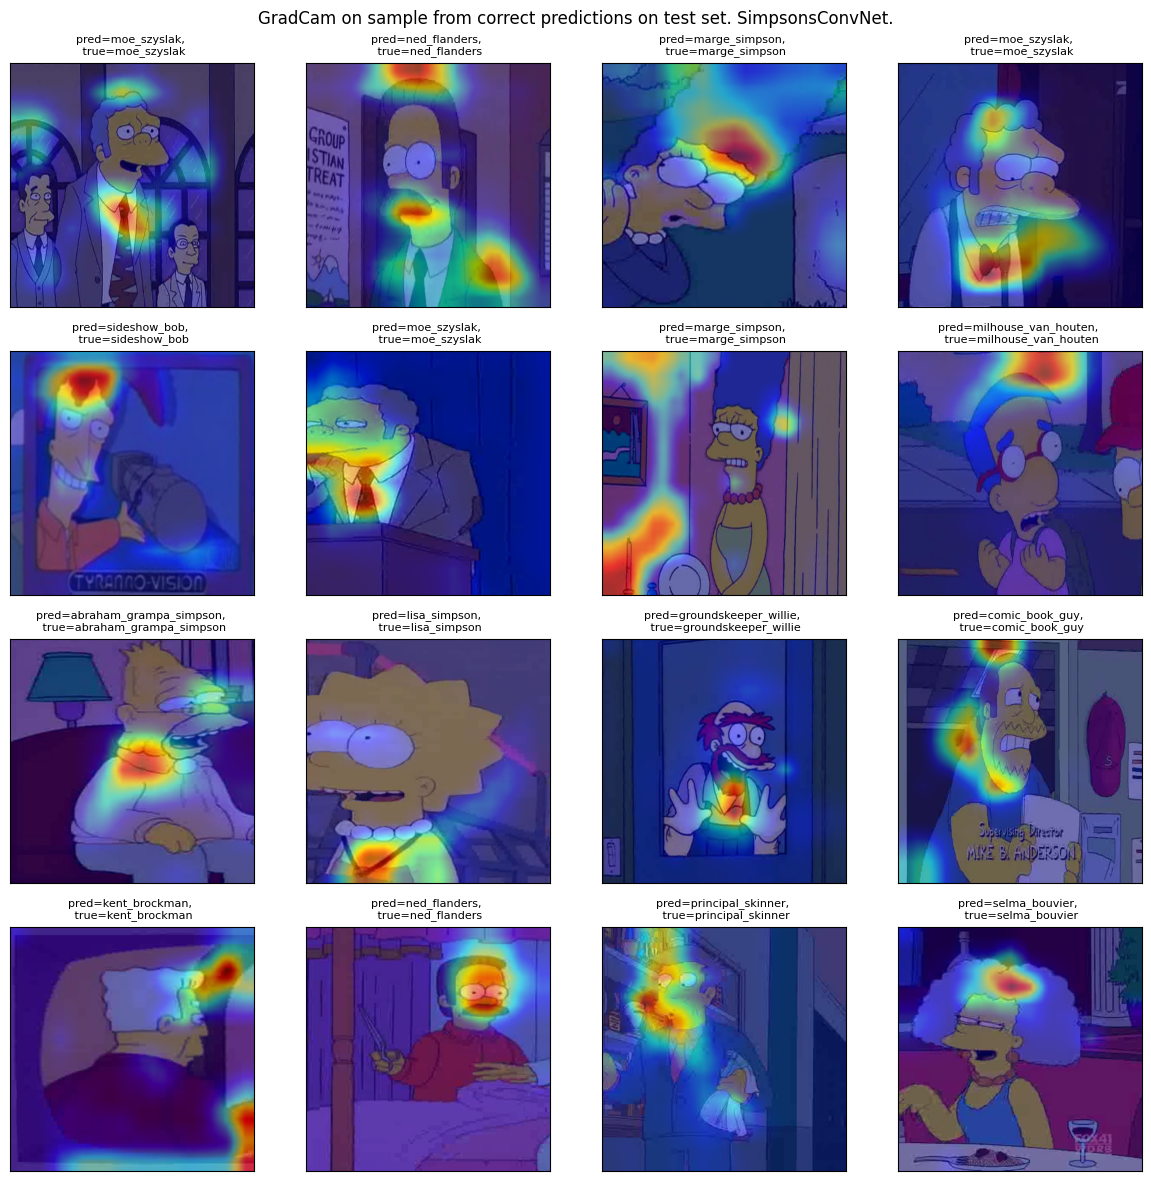

In [34]:
fig, ax_arr = plt.subplots(4, 4, figsize=(12, 12))

fig.suptitle("GradCam on sample from correct predictions on test set. SimpsonsConvNet.")

sample = np.array(correct)[np.random.choice(len(correct), 16, replace=False)]

for i, ax in enumerate(ax_arr.flatten()):
    sample_id = sample[i][0]

    cls_pred = sample[i][2]
    cls_true = sample[i][3]

    ax.tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)

    ax.imshow(np.array(
        apply_gradcam(
            input_idx=sample_id,
            dataset_raw=dataset_full,
            dataset_processed=dataset_64x64,
            model=model,
            target_layers=list(model.children())[-11:-6]
        )
    ))
    ax.set_title(f"pred={cls_pred}, \n true={cls_true}", fontsize=8)

fig.tight_layout()